# Notebook 03 — Baseline and Core Models

This notebook compares a majority-class baseline, Logistic Regression, a Decision Tree and K-Nearest Neighbors with the **same 5-fold stratified cross-validation and the same metrics** on the training set only (36,168 rows). All models use default hyperparameters (plus `class_weight="balanced"` where available), and the leakage-free pipeline of Notebook 02 is re-fitted inside every fold. Run the notebooks in the order 01 → 05 and execute all cells from the top (*Restart* → *Run All*).

## 1. Setup

This section imports the libraries and project modules and recreates the identical train/test split.

In [1]:
# Make the project's src/ package importable (notebooks live in notebooks/)
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

# Hide FutureWarnings from libraries so that the outputs stay readable
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import validation_curve
from sklearn.tree import DecisionTreeClassifier

# Project modules: figure style, paths, split/pipeline helpers, models and CV utilities
from src.plot_style import apply_style, BLUE, ORANGE, GREY
from src.config import FIGURES_DIR, RESULTS_DIR, RANDOM_STATE
from src.data_loader import load_raw_data
from src.preprocessing import split_data, build_model_pipeline
from src.train_models import CV, get_baseline_and_core_models, cross_validate_models
from src.evaluate import format_cv_table

apply_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Same stratified split as Notebook 02 (random_state=42); X_test / y_test are NOT used here
df = load_raw_data()
X_train, X_test, y_train, y_test = split_data(df)
print("Training rows:", len(X_train), "| share of yes:", round(y_train.mean(), 4))

Training rows: 36168 | share of yes: 0.117


## 2. Validation Scheme

This section shows the stratified 5-fold cross-validation used for every model: each model is trained on 4 folds and validated on the 5th, five times, and we report the mean and standard deviation.

In [2]:
# Size and share of "yes" of every training/validation fold
for k, (tr_idx, va_idx) in enumerate(CV.split(X_train, y_train), start=1):
    print(f"Fold {k}: train={len(tr_idx):,} rows ({y_train.iloc[tr_idx].mean():.2%} yes) | "
          f"validation={len(va_idx):,} rows ({y_train.iloc[va_idx].mean():.2%} yes)")

Fold 1: train=28,934 rows (11.70% yes) | validation=7,234 rows (11.69% yes)
Fold 2: train=28,934 rows (11.70% yes) | validation=7,234 rows (11.69% yes)
Fold 3: train=28,934 rows (11.70% yes) | validation=7,234 rows (11.71% yes)
Fold 4: train=28,935 rows (11.70% yes) | validation=7,233 rows (11.70% yes)
Fold 5: train=28,935 rows (11.70% yes) | validation=7,233 rows (11.70% yes)


**Why ROC-AUC is the main metric.** It is 0.5 for a constant predictor regardless of the imbalance, it measures how well clients are **ranked** (exactly what a call list needs), and it does not depend on a decision threshold, which is chosen later (Notebook 04). Average precision, F1, precision, recall and accuracy are reported as well.

## 3. The Models

This section defines the baseline and the three core algorithms.

| Model | Why it is suitable for this data | Main weakness |
|---|---|---|
| **Dummy (majority class)** | Reference point that any real model must beat | Learns nothing; always predicts "no" |
| **Logistic Regression** | Simple, fast, interpretable linear model; works well with one-hot features; gives probabilities | Linear boundary only; cannot capture the U-shaped age effect or interactions |
| **Decision Tree** | Learns non-linear rules and interactions; easy to explain; needs no scaling | A fully grown tree memorises the training data (high variance) |
| **K-Nearest Neighbors (k=5)** | Non-parametric: no assumption about the shape of the boundary | Distances are less meaningful with 51 mostly binary features; slow prediction; no class weights |

In [3]:
# Baseline + three core models with their (default) settings
models = get_baseline_and_core_models()
for name, model in models.items():
    print(f"{name:<25} {model}")

Dummy (majority class)    DummyClassifier(strategy='most_frequent')
Logistic Regression       LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
Decision Tree             DecisionTreeClassifier(class_weight='balanced', random_state=42)
K-Nearest Neighbors       KNeighborsClassifier()


## 4. Baseline Model — DummyClassifier

This section evaluates the majority-class baseline that every real model must beat.

In [4]:
# 5-fold CV of the majority-class baseline
baseline = cross_validate_models({"Dummy (majority class)": models["Dummy (majority class)"]}, X_train, y_train)
format_cv_table(baseline)

Dummy (majority class)    ROC-AUC = 0.5000 +/- 0.0000   (4 s)


,Model,roc_auc,average_precision,f1,precision,recall,accuracy
0,Dummy (majority class),0.500 ± 0.000,0.117 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.883 ± 0.000


**Interpretation.** The baseline reaches **88.3 % accuracy** but 0 recall, 0 precision and F1 = 0: it never finds a subscriber. Its ROC-AUC is 0.5 and its average precision equals the positive share (0.117), which shows that accuracy alone is misleading here.

## 5. Core Models — Cross-Validation Results

This section evaluates the three core algorithms with the same folds and metrics.

In [5]:
# Cross-validate the three core models and combine them with the baseline
core_names = ["Logistic Regression", "Decision Tree", "K-Nearest Neighbors"]
core = cross_validate_models({n: models[n] for n in core_names}, X_train, y_train)
cv_core = pd.concat([baseline, core], ignore_index=True)
cv_core.to_csv(RESULTS_DIR / "cv_results_core.csv", index=False)

# Mean +/- std of every metric over the 5 folds
table_core = format_cv_table(cv_core)
table_core

Logistic Regression       ROC-AUC = 0.7637 +/- 0.0032   (3 s)


Decision Tree             ROC-AUC = 0.6046 +/- 0.0056   (3 s)


K-Nearest Neighbors       ROC-AUC = 0.6920 +/- 0.0084   (14 s)


,Model,roc_auc,average_precision,f1,precision,recall,accuracy
0,Dummy (majority class),0.500 ± 0.000,0.117 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.883 ± 0.000
1,Logistic Regression,0.764 ± 0.003,0.398 ± 0.007,0.373 ± 0.003,0.266 ± 0.004,0.623 ± 0.010,0.755 ± 0.005
2,Decision Tree,0.605 ± 0.006,0.172 ± 0.004,0.301 ± 0.009,0.298 ± 0.008,0.304 ± 0.011,0.835 ± 0.002
3,K-Nearest Neighbors,0.692 ± 0.008,0.283 ± 0.011,0.299 ± 0.022,0.537 ± 0.031,0.208 ± 0.017,0.886 ± 0.003


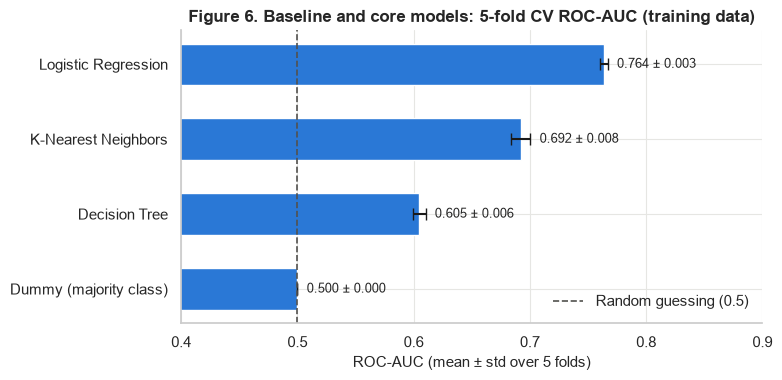

In [6]:
# Figure 6: mean CV ROC-AUC with the standard deviation as error bar
plot_df = cv_core.sort_values("roc_auc_mean")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(plot_df["model"], plot_df["roc_auc_mean"], xerr=plot_df["roc_auc_std"],
        color=BLUE, height=0.55, capsize=4)
for i, (m, s) in enumerate(zip(plot_df["roc_auc_mean"], plot_df["roc_auc_std"])):
    ax.text(m + s + 0.008, i, f"{m:.3f} ± {s:.3f}", va="center", fontsize=9)
ax.axvline(0.5, ls="--", color=GREY, lw=1.2, label="Random guessing (0.5)")
ax.set_xlim(0.4, 0.9)
ax.set_title("Figure 6. Baseline and core models: 5-fold CV ROC-AUC (training data)")
ax.set_xlabel("ROC-AUC (mean ± std over 5 folds)")
ax.set_ylabel("")
ax.legend(loc="lower right")
fig.savefig(FIGURES_DIR / "fig06_core_models_cv_auc.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation (Figure 6).**
* **Logistic Regression** is the best and most stable core model (ROC-AUC **0.764 ± 0.003**); with balanced class weights it finds 62 % of subscribers at a low precision (0.27).
* **KNN** (0.692) has high precision (0.54) but low recall (0.21), because without class weights the vote of 5 neighbours is usually "no".
* The fully grown **Decision Tree** is the weakest real model (0.605), and its accuracy (0.835) is even below the baseline's.
* All core models clearly beat the baseline, and the small standard deviations show that the ranking is stable.

## 6. Training vs Validation Performance

This section compares training-fold and validation-fold scores: a large gap indicates over-fitting (high variance), two low scores indicate under-fitting (high bias).

In [7]:
# Training-fold vs validation-fold scores from cross_validate(return_train_score=True)
gap = pd.DataFrame({
    "Model": cv_core["model"],
    "Train ROC-AUC": cv_core["train_roc_auc_mean"].round(3),
    "Validation ROC-AUC": cv_core["roc_auc_mean"].round(3),
    "Gap": (cv_core["train_roc_auc_mean"] - cv_core["roc_auc_mean"]).round(3),
    "Train F1": cv_core["train_f1_mean"].round(3),
    "Validation F1": cv_core["f1_mean"].round(3),
})
gap

,Model,Train ROC-AUC,Validation ROC-AUC,Gap,Train F1,Validation F1
0,Dummy (majority class),0.500,0.500,0.000,0.000,0.000
1,Logistic Regression,0.769,0.764,0.005,0.377,0.373
2,Decision Tree,1.000,0.605,0.395,1.000,0.301
3,K-Nearest Neighbors,0.919,0.692,0.227,0.430,0.299


**Interpretation.** The Decision Tree (training 1.000 vs validation 0.605) and KNN (gap 0.227) over-fit strongly, while Logistic Regression has almost no gap (0.005) but a lower score, i.e. its limit is bias. This is the classic bias–variance picture.

## 7. Validation Curve of the Decision Tree

This section varies the tree's `max_depth` to show the transition from under-fitting to over-fitting directly (same folds, training data only).

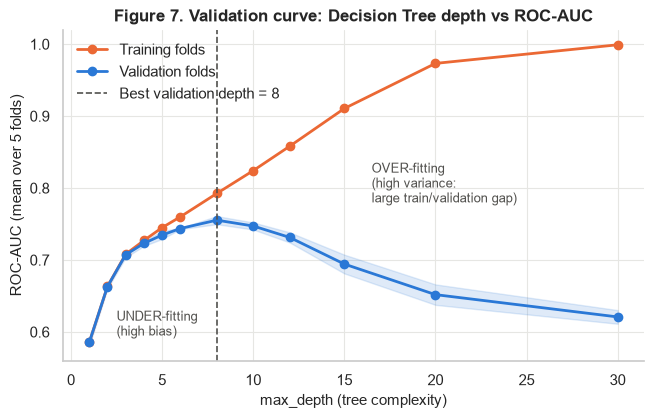

,max_depth,train_auc,val_auc,val_std
0,1,0.585,0.585,0.005
1,2,0.663,0.663,0.003
2,3,0.708,0.707,0.004
3,4,0.727,0.723,0.004
4,5,0.745,0.735,0.006
5,6,0.760,0.744,0.001
6,8,0.792,0.755,0.006
7,10,0.824,0.747,0.005
8,12,0.858,0.731,0.007
9,15,0.911,0.694,0.013


In [8]:
# Training and validation ROC-AUC for increasing tree depth
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30]
tree_pipe = build_model_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))
train_scores, val_scores = validation_curve(
    tree_pipe, X_train, y_train, param_name="model__max_depth", param_range=depths,
    cv=CV, scoring="roc_auc", n_jobs=-1)

vc = pd.DataFrame({"max_depth": depths, "train_auc": train_scores.mean(axis=1),
                   "val_auc": val_scores.mean(axis=1), "val_std": val_scores.std(axis=1)})
best_depth = int(vc.loc[vc["val_auc"].idxmax(), "max_depth"])

# Figure 7: both curves with the +/- 1 std band of the validation score
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(vc["max_depth"], vc["train_auc"], "o-", color=ORANGE, lw=2, label="Training folds")
ax.plot(vc["max_depth"], vc["val_auc"], "o-", color=BLUE, lw=2, label="Validation folds")
ax.fill_between(vc["max_depth"], vc["val_auc"] - vc["val_std"], vc["val_auc"] + vc["val_std"],
                color=BLUE, alpha=0.15)
ax.axvline(best_depth, ls="--", color=GREY, lw=1.2, label=f"Best validation depth = {best_depth}")
ax.text(2.5, 0.595, "UNDER-fitting\n(high bias)", fontsize=9, color=GREY)
ax.text(16.5, 0.78, "OVER-fitting\n(high variance:\nlarge train/validation gap)", fontsize=9, color=GREY)
ax.set_title("Figure 7. Validation curve: Decision Tree depth vs ROC-AUC")
ax.set_xlabel("max_depth (tree complexity)")
ax.set_ylabel("ROC-AUC (mean over 5 folds)")
ax.legend(loc="upper left")
fig.savefig(FIGURES_DIR / "fig07_tree_validation_curve.png", dpi=150, bbox_inches="tight")
plt.show()
vc.round(3)

**Interpretation (Figure 7).** At depths 1–3 both scores are equal and low (under-fitting); both rise until **max_depth = 8** (validation ROC-AUC 0.755); beyond that the training score approaches 1.0 while the validation score falls (over-fitting). Even the best single tree stays below Logistic Regression, which motivates the ensembles in Notebook 04.

## 8. Logistic Regression Coefficients

This section shows which features push the log-odds of subscribing up or down (numeric features are standardised, so their coefficients are comparable).

In [9]:
# Fit Logistic Regression on the full training set and read its coefficients
lr = build_model_pipeline(models["Logistic Regression"]).fit(X_train, y_train)
coefs = pd.Series(lr.named_steps["model"].coef_[0],
                  index=lr.named_steps["preprocessor"].get_feature_names_out())
coefs.index = coefs.index.str.replace("num__", "").str.replace("cat__", "")

# Short table: the 8 most positive and the 8 most negative coefficients (change in log-odds)
top_pos, top_neg = coefs.nlargest(8), coefs.nsmallest(8)
pd.DataFrame({
    "increases subscription": top_pos.index, "coef (+)": top_pos.values.round(3),
    "decreases subscription": top_neg.index, "coef (-)": top_neg.values.round(3),
}, index=pd.RangeIndex(1, 9, name="rank"))

,increases subscription,coef (+),decreases subscription,coef (-)
rank,,,,
1,poutcome_success,1.498,month_jan,-1.058
2,month_mar,1.211,poutcome_failure,-0.850
3,month_oct,0.924,month_nov,-0.796
4,month_dec,0.846,month_aug,-0.751
5,month_sep,0.781,contact_unknown,-0.740
6,job_retired,0.502,month_jul,-0.603
7,contact_cellular,0.456,poutcome_other,-0.592
8,job_student,0.340,month_may,-0.435


**Interpretation.** The strongest positive effects are a successful previous campaign and the quiet months March, October, December and September, followed by retired clients, cellular contact and students; negative effects include `poutcome_failure`, unknown contact type and the busy months. These agree with the EDA (Figures 2–4), so the model learned real patterns rather than noise.

## 9. Summary

| Model | CV ROC-AUC (mean ± std) | Main observation |
|---|---|---|
| Dummy | 0.500 ± 0.000 | 88 % accuracy but finds no subscriber |
| Logistic Regression | 0.764 ± 0.003 | best core model; stable and interpretable; slight under-fitting (bias) |
| Decision Tree | 0.605 ± 0.006 | strong over-fitting (train 1.000) |
| KNN | 0.692 ± 0.008 | over-fitting, low recall |

All core models beat the baseline. The results are saved in `results/cv_results_core.csv` and compared with the ensembles in Notebook 04.